## Importing Libraries

In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision

In [2]:
from torchvision.datasets import CIFAR10
from torch.utils.data import DataLoader
import torchvision.transforms as transforms

In [3]:
transform=transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,0.5,0.5),(0.5,0.5,0.5))
])
trainset=CIFAR10(root="./data",train=True,download=True,transform=transform)
testset=CIFAR10(root="./data",train=False,download=True,transform=transform)


In [4]:
trainset

Dataset CIFAR10
    Number of datapoints: 50000
    Root location: ./data
    Split: Train
    StandardTransform
Transform: Compose(
               ToTensor()
               Normalize(mean=(0.5, 0.5, 0.5), std=(0.5, 0.5, 0.5))
           )

In [5]:
trainloader=DataLoader(trainset,batch_size=64,shuffle=True)
testloader=DataLoader(testset,batch_size=64)

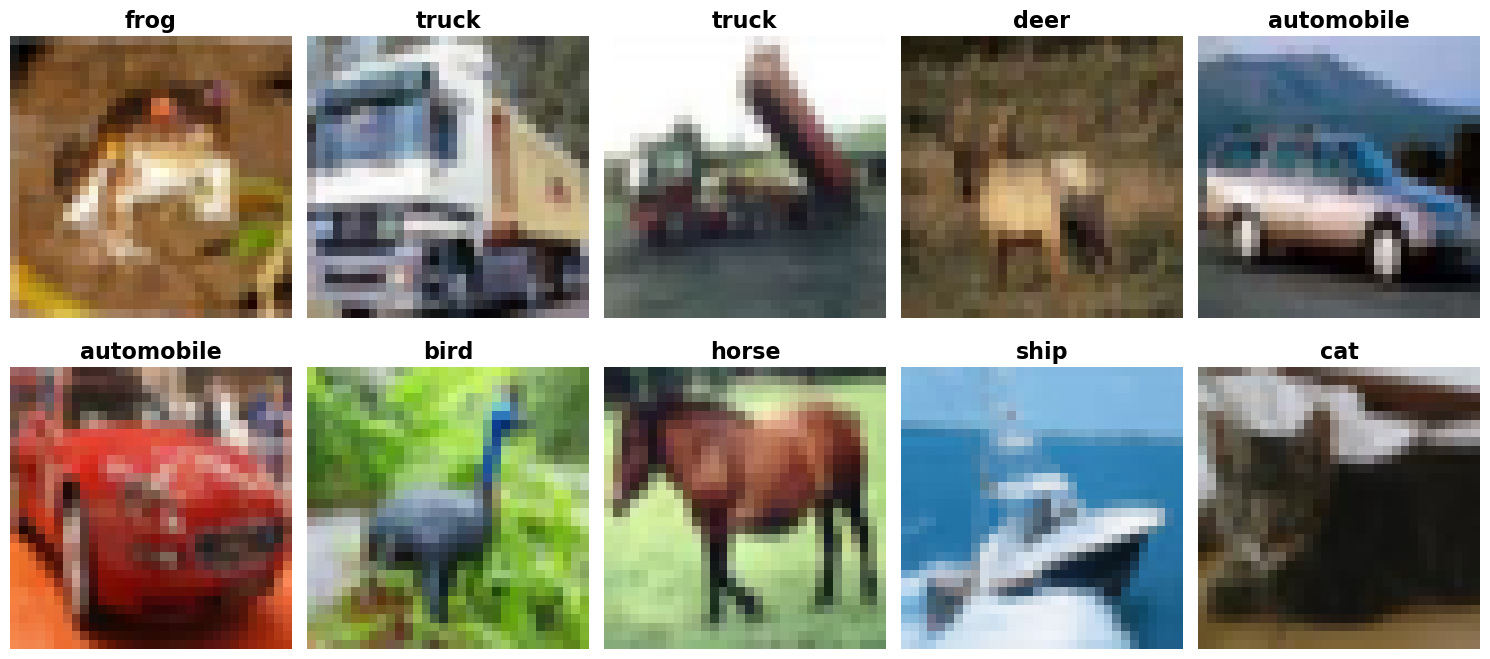

In [31]:
import matplotlib.pyplot as plt

classes = trainset.classes
fig, axes = plt.subplots(2, 5, figsize=(15, 7))
for i, ax in enumerate(axes.flat):
    img, label = trainset[i]
    img = (img / 2 + 0.5).permute(1, 2, 0).numpy()   # un-normalize
    ax.imshow(img, interpolation="nearest")           # smooth upscaling
    ax.set_title(classes[label], fontsize=16, fontweight="bold")
    ax.axis("off")
plt.tight_layout()
plt.savefig("samples.png", dpi=300, bbox_inches="tight", facecolor="white")

In [6]:
class CNN(nn.Module):
    def __init__(self):
        super(CNN,self).__init__()
        self.conv_layers=nn.Sequential(
            nn.Conv2d(3,32,kernel_size=3,padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2,2),
            nn.Conv2d(32,64,kernel_size=3,padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2,2),
            nn.Conv2d(64,128,kernel_size=3,padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2,2),
            
        )
        self.fc_layers=nn.Sequential(
            nn.Linear(4*4*128,256),
            nn.ReLU(),
            nn.Linear(256,10)
        )
    def forward(self,x):
        x=self.conv_layers(x)
        x=x.view(x.shape[0],-1)
        x=self.fc_layers(x)
        return x

In [7]:
model=CNN()
criterion=nn.CrossEntropyLoss()
optimizer=optim.Adam(model.parameters())

## Training the CNN

In [8]:
epochs=10
for epoch in range (epochs):
    epoch_training_loss=0
    for images,labels in trainloader:
        optimizer.zero_grad()
        output=model.forward(images)
        loss=criterion(output,labels)
        loss.backward()
        optimizer.step()
        epoch_training_loss +=loss.item()
    print(f"for epoch {epoch+1}/{epochs} and loss {epoch_training_loss/len(trainloader)}")

for epoch 1/10 and loss 1.4010392380949785
for epoch 2/10 and loss 0.9502484856359185
for epoch 3/10 and loss 0.7577021728315012
for epoch 4/10 and loss 0.6368625521126305
for epoch 5/10 and loss 0.5254157595622265
for epoch 6/10 and loss 0.43844320226813216
for epoch 7/10 and loss 0.35549987899258617
for epoch 8/10 and loss 0.27693486656717325
for epoch 9/10 and loss 0.2140665987787573
for epoch 10/10 and loss 0.17277987458554986


## Evaluating the Model

In [13]:
correct_labels=0
total_labels=0
model.eval()
with torch.no_grad():
    for images,labels in testloader:
        outputs=model.forward(images)
        _,predicted=torch.max(outputs,1)
        correct_labels += (predicted==labels).sum().item()
        total_labels += labels.size(0)
    print(f"accracy_score:{correct_labels/total_labels*100}")

accracy_score:75.81


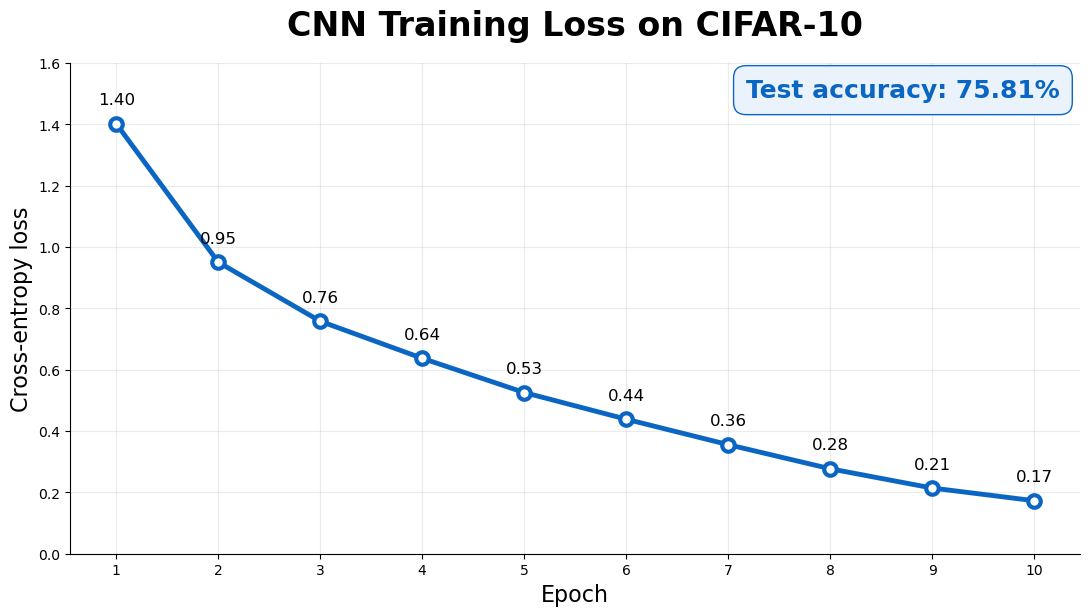

In [29]:
loss = [1.4010, 0.9502, 0.7577, 0.6369, 0.5254,
        0.4384, 0.3555, 0.2769, 0.2141, 0.1728]
epochs = list(range(1, 11))

fig, ax = plt.subplots(figsize=(11, 6.27))
ax.plot(epochs, loss, color="#0A66C2", lw=3.5, marker="o", ms=9, mfc="white", mew=3)

for x, y in zip(epochs, loss):
    ax.annotate(f"{y:.2f}", (x, y), textcoords="offset points",
                xytext=(0, 14), ha="center", fontsize=12)

ax.set_title("CNN Training Loss on CIFAR-10", fontsize=24, fontweight="bold", pad=20)
ax.set_xlabel("Epoch", fontsize=16)
ax.set_ylabel("Cross-entropy loss", fontsize=16)
ax.set_xticks(epochs)
ax.set_ylim(0, 1.6)
ax.grid(alpha=0.25)
ax.spines[["top", "right"]].set_visible(False)

ax.text(0.98, 0.93, "Test accuracy: 75.81%", transform=ax.transAxes,
        ha="right", fontsize=18, fontweight="bold", color="#0A66C2",
        bbox=dict(boxstyle="round,pad=0.5", fc="#EAF3FC", ec="#0A66C2"))

plt.tight_layout()
plt.savefig("loss_curve.png", dpi=300, bbox_inches="tight")
plt.show()

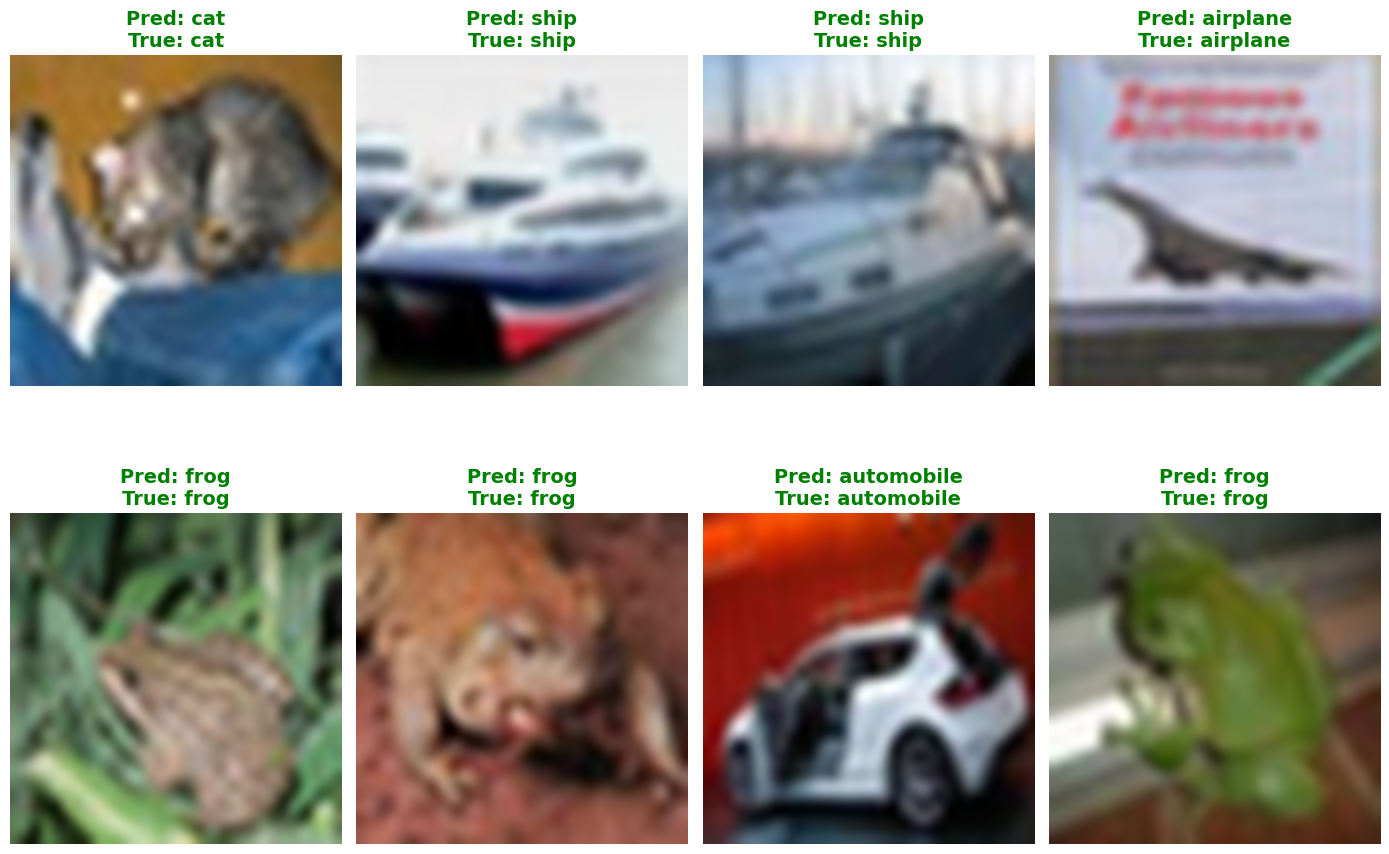

In [34]:
import torch, matplotlib.pyplot as plt

model.eval()
images, labels = next(iter(testloader))
with torch.no_grad():
    preds = model(images).argmax(1)

fig, axes = plt.subplots(2, 4, figsize=(14, 10))
for ax, img, y, p in zip(axes.flat, images, labels, preds):
    ax.imshow((img / 2 + 0.5).permute(1, 2, 0).numpy(), interpolation="lanczos")
    ok = y == p
    ax.set_title(f"Pred: {classes[p]}\nTrue: {classes[y]}",
                 color="green" if ok else "red", fontsize=14, fontweight="bold")
    ax.axis("off")
plt.tight_layout()
plt.savefig("predictions.png", dpi=300, bbox_inches="tight", facecolor="white")